In [11]:
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
file_path = '/content/drive/MyDrive/SEMESTER 5/DATA SCIENCE/sesi3/Dataset_Transaksi_Inferensial.csv'

membaca dataset

In [6]:
df = pd.read_csv ('/content/drive/MyDrive/SEMESTER 5/DATA SCIENCE/sesi3/Dataset_Transaksi_Inferensial.csv')
print("=== 5 baris pertama data ===")
print(df.head())
print("\n" + "="*50 + "\n")

=== 5 baris pertama data ===
   ID_Transaksi Warna_Tombol   Metode_Bayar  Waktu_Akses_Menit  \
0             1         Biru       E-Wallet                5.2   
1             2        Hijau  Transfer Bank               12.5   
2             3         Biru   Kartu Kredit                3.1   
3             4        Hijau       E-Wallet                8.0   
4             5         Biru       E-Wallet                4.5   

   Nominal_Transaksi  
0             150000  
1             250000  
2             350000  
3             175000  
4             120000  




Uji Hipotesis (A/B Testing dengan Independent T-Test)

In [17]:
grup_biru = df[df['Warna_Tombol'] == 'Biru']['Nominal_Transaksi']
grup_hijau = df[df['Warna_Tombol'] == 'Hijau']['Nominal_Transaksi']

t_stat, p_val_ttest = stats.ttest_ind(grup_biru, grup_hijau)
print(f"T-Statistic: {t_stat:.4f}")
print(f"P-Value: {p_val_ttest:.4f}")

if p_val_ttest < 0.05:
    print("Kesimpulan: Tolak H0. Ada perbedaan nominal transaksi yang signifikan antara tombol Biru dan Hijau.")
else:
    print("Kesimpulan: Gagal Tolak H0. Tidak ada perbedaan nominal transaksi yang signifikan antara tombol Biru dan Hijau.")

T-Statistic: -1.3227
P-Value: 0.2025
Kesimpulan: Gagal Tolak H0. Tidak ada perbedaan nominal transaksi yang signifikan antara tombol Biru dan Hijau.


Analysis of Variance (One-Way ANOVA)

In [20]:
ewallet = df[df['Metode_Bayar'] == 'E-Wallet']['Nominal_Transaksi']
transfer = df[df['Metode_Bayar'] == 'Transfer Bank']['Nominal_Transaksi']
kartu_kredit = df[df['Metode_Bayar'] == 'Kartu Kredit']['Nominal_Transaksi']

f_stat, p_val_anova = stats.f_oneway(ewallet, transfer, kartu_kredit)
print(f"Nilai F-Statistic: {f_stat:.4f}")
print(f"Nilai P-Value: {p_val_anova:.4f}")

if p_val_anova < 0.05:
    print("Kesimpulan: Tolak H0. Ada perbedaan rata-rata transaksi yang signifikan antar metode pembayaran.")
else:
    print("Kesimpulan: Gagal Tolak H0. Tidak ada perbedaan yang signifikan.")

Nilai F-Statistic: 76.7215
Nilai P-Value: 0.0000
Kesimpulan: Tolak H0. Ada perbedaan rata-rata transaksi yang signifikan antar metode pembayaran.


Menguji Korelasi Variabel

Koefisien Korelasi (r): 0.5556
P-Value: 0.0110


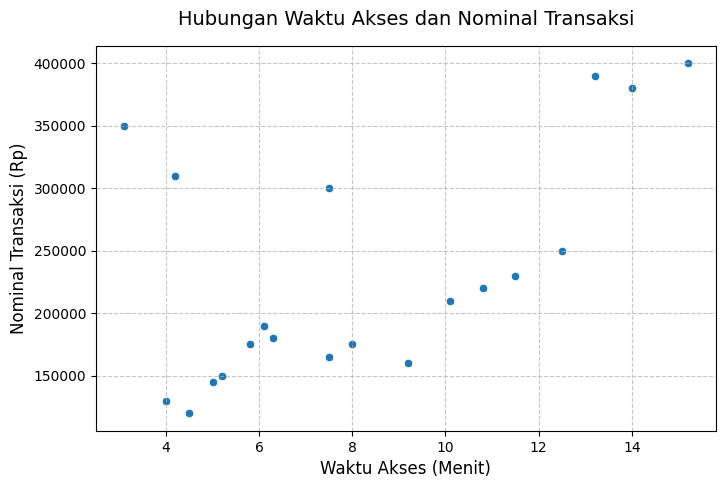

In [19]:
korelasi, p_val_corr = stats.pearsonr(df['Waktu_Akses_Menit'], df['Nominal_Transaksi'])
print(f"Koefisien Korelasi (r): {korelasi:.4f}")
print(f"P-Value: {p_val_corr:.4f}")

plt.figure(figsize=(8, 5))
sns.scatterplot(x='Waktu_Akses_Menit', y='Nominal_Transaksi', data=df)
plt.title('Hubungan Waktu Akses dan Nominal Transaksi', fontsize=14, pad=15)
plt.xlabel('Waktu Akses (Menit)', fontsize=12)
plt.ylabel('Nominal Transaksi (Rp)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()